In [1]:
import sys
import os

# Add src/ to path regardless of current working directory
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_utils import load_transactions

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

In [2]:
df = load_transactions(path=os.path.join(project_root, "data", "HI-Small_Trans.csv"))
print(df.shape)
df.head()

(5078345, 11)


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022-09-01 00:20:00,10,8000EBD30,10,8000EBD30,3697.340088,US Dollar,3697.340088,US Dollar,Reinvestment,0
1,2022-09-01 00:20:00,3208,8000F4580,1,8000F5340,0.010000,US Dollar,0.010000,US Dollar,Cheque,0
2,2022-09-01 00:00:00,3209,8000F4670,3209,8000F4670,14675.570312,US Dollar,14675.570312,US Dollar,Reinvestment,0
3,2022-09-01 00:02:00,12,8000F5030,12,8000F5030,2806.969971,US Dollar,2806.969971,US Dollar,Reinvestment,0
4,2022-09-01 00:06:00,10,8000F5200,10,8000F5200,36682.968750,US Dollar,36682.968750,US Dollar,Reinvestment,0


In [3]:
print("Date range:", df["Timestamp"].min(), "to", df["Timestamp"].max())
print("Total days:", (df["Timestamp"].max() - df["Timestamp"].min()).days)
print()
print("Amount Paid stats:")
print(df["Amount Paid"].describe())
print()
print("Same-bank vs cross-bank transactions:")
print((df["From Bank"] == df["To Bank"]).value_counts())

Date range: 2022-09-01 00:00:00 to 2022-09-18 16:18:00
Total days: 17

Amount Paid stats:
count    5.078345e+06
mean     4.509274e+06
std      8.697729e+08
min      1.000000e-06
25%      1.844800e+02
50%      1.414540e+03
75%      1.229784e+04
max      1.046302e+12
Name: Amount Paid, dtype: float64

Same-bank vs cross-bank transactions:
False    4387013
True      691332
Name: count, dtype: int64


In [4]:
print("Payment Currency distribution:")
print(df["Payment Currency"].value_counts())
print()
print("Payment Format distribution:")
print(df["Payment Format"].value_counts())

Payment Currency distribution:
Payment Currency
US Dollar            1895172
Euro                 1168297
Swiss Franc           234860
Yuan                  213752
Shekel                192184
Rupee                 190202
UK Pound              180738
Yen                   155209
Ruble                 155178
Bitcoin               146066
Canadian Dollar       140042
Australian Dollar     136769
Mexican Peso          110159
Saudi Riyal            89014
Brazil Real            70703
Name: count, dtype: int64

Payment Format distribution:
Payment Format
Cheque          1864331
Credit Card     1323324
ACH              600797
Cash             490891
Reinvestment     481056
Wire             171855
Bitcoin          146091
Name: count, dtype: int64


In [6]:
normal = df[df["Is Laundering"] == 0]
laundering = df[df["Is Laundering"] == 1]

print("=== Amount Paid: Normal vs Laundering ===")
print("Normal:    ", normal["Amount Paid"].describe())
print()
print("Laundering:", laundering["Amount Paid"].describe())
print()

print("=== Payment Format: Normal vs Laundering (%) ===")
comparison = pd.DataFrame({
    "Normal %": normal["Payment Format"].value_counts(normalize=True) * 100,
    "Laundering %": laundering["Payment Format"].value_counts(normalize=True) * 100,
})
print(comparison)
print()

print("=== Cross-bank rate: Normal vs Laundering ===")
print("Normal cross-bank rate:    ", (normal["From Bank"] != normal["To Bank"]).mean())
print("Laundering cross-bank rate:", (laundering["From Bank"] != laundering["To Bank"]).mean())

=== Amount Paid: Normal vs Laundering ===
Normal:     count    5.073168e+06
mean     4.477000e+06
std      8.688463e+08
min      1.000000e-06
25%      1.841600e+02
50%      1.410990e+03
75%      1.227934e+04
max      1.046302e+12
Name: Amount Paid, dtype: float64

Laundering: count    5.177000e+03
mean     3.613531e+07
std      1.527919e+09
min      3.227000e-03
25%      2.634970e+03
50%      8.667210e+03
75%      1.883227e+04
max      8.485315e+10
Name: Amount Paid, dtype: float64

=== Payment Format: Normal vs Laundering (%) ===
                 Normal %  Laundering %
Payment Format                         
ACH             11.754273     86.594553
Bitcoin          2.878576      1.081708
Cash             9.674093      2.086150
Cheque          36.742465      6.258451
Credit Card     26.080705      3.979138
Reinvestment     9.482359      0.000000
Wire             3.387528      0.000000

=== Cross-bank rate: Normal vs Laundering ===
Normal cross-bank rate:     0.8637480564412612
Launderin

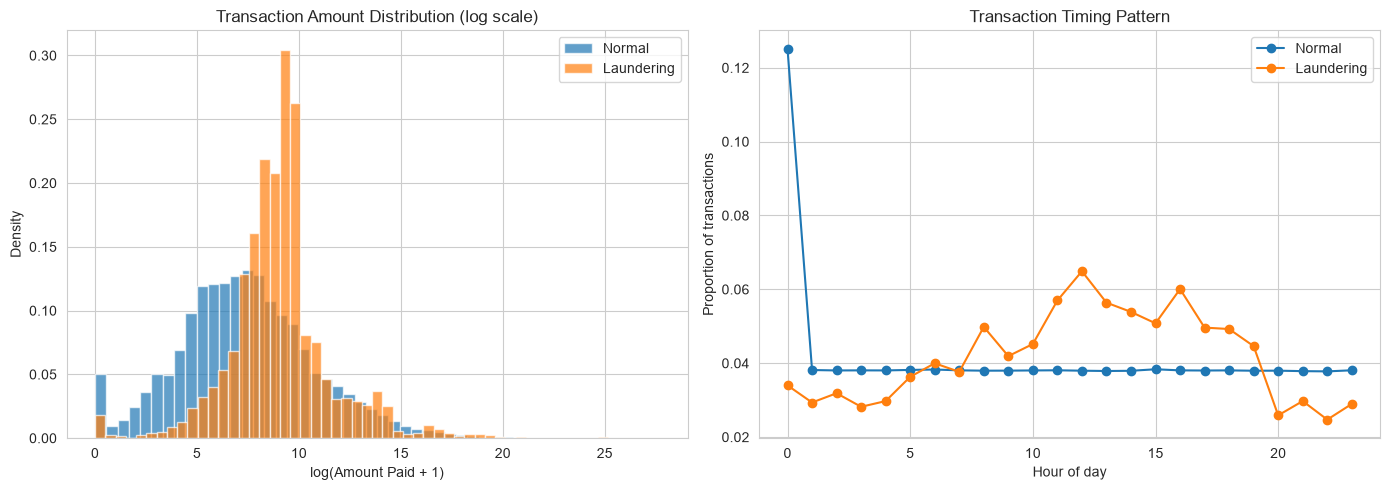

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(np.log1p(normal["Amount Paid"]), bins=50, alpha=0.7, label="Normal", density=True)
axes[0].hist(np.log1p(laundering["Amount Paid"]), bins=50, alpha=0.7, label="Laundering", density=True)
axes[0].set_xlabel("log(Amount Paid + 1)")
axes[0].set_ylabel("Density")
axes[0].set_title("Transaction Amount Distribution (log scale)")
axes[0].legend()

df["hour"] = df["Timestamp"].dt.hour
normal_hourly = df[df["Is Laundering"] == 0]["hour"].value_counts(normalize=True).sort_index()
laundering_hourly = df[df["Is Laundering"] == 1]["hour"].value_counts(normalize=True).sort_index()

axes[1].plot(normal_hourly.index, normal_hourly.values, label="Normal", marker="o")
axes[1].plot(laundering_hourly.index, laundering_hourly.values, label="Laundering", marker="o")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Proportion of transactions")
axes[1].set_title("Transaction Timing Pattern")
axes[1].legend()

plt.tight_layout()
plt.show()

In [8]:
comparison = pd.DataFrame({
    "Normal %": normal["Payment Format"].value_counts(normalize=True) * 100,
    "Laundering %": laundering["Payment Format"].value_counts(normalize=True) * 100,
})
print(comparison)

                 Normal %  Laundering %
Payment Format                         
ACH             11.754273     86.594553
Bitcoin          2.878576      1.081708
Cash             9.674093      2.086150
Cheque          36.742465      6.258451
Credit Card     26.080705      3.979138
Reinvestment     9.482359      0.000000
Wire             3.387528      0.000000


In [9]:
print(pd.crosstab(df["hour"], df["Payment Format"], normalize="index").round(3) * 100)

Payment Format   ACH  Bitcoin  Cash  Cheque  Credit Card  Reinvestment  Wire
hour                                                                        
0                6.2      2.9   4.3    16.3         31.5          37.2   1.6
1               12.5      3.0  10.5    39.7         25.4           5.4   3.6
2               12.6      2.8  10.4    39.6         25.2           5.6   3.7
3               12.4      2.8  10.5    39.7         25.4           5.5   3.7
4               12.6      2.9  10.3    39.8         25.4           5.5   3.6
5               12.9      2.9  10.4    39.5         25.2           5.4   3.6
6               12.8      2.8  10.4    39.6         25.3           5.5   3.6
7               12.7      2.9  10.5    39.6         25.1           5.6   3.7
8               12.9      2.9  10.4    39.6         25.2           5.4   3.6
9               12.6      2.9  10.5    39.6         25.2           5.5   3.7
10              12.8      2.8  10.5    39.6         25.3           5.5   3.6